In [ ]:
# Moved to other_experiments/: run from the FLIP repo root so relative paths (data/, experiments/,
# noise_generator/, ...) and `import modules...` keep working. Safe to re-run.
import os, sys
from pathlib import Path
_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'run_experiment.py').is_file())
os.chdir(_root)
for _p in (str(_root), str(_root / 'modules')):
    if _p not in sys.path: sys.path.insert(0, _p)

# Label-hiding encoders: analysis and noise

Six `TriggerEncoder`s trained on all of CIFAR-10 with a random hidden label per image. The noise is capped at |δ| ≤ 6/255 by the encoder's tanh, and there is no MSE term. Every encoder is trained jointly with a 10-class `TriggerDecoder`.

| Encoder | Decoder | Surrogate (adversarial loss) | Discriminator |
|---|---|---|---|
| `s1_nodisc_noadv` | yes | none | no |
| `s2_nodisc_adv_resnet18` | yes | ResNet-18 | no |
| `s2_nodisc_adv_resnet32` | yes | ResNet-32 | no |
| `s2_nodisc_adv_efficientnet` | yes | EfficientNet | no |
| `s3_disc_noadv` | yes | none | yes |
| `s4_disc_adv_resnet18` | yes | ResNet-18 | yes |

**How to read the metrics.** A hidden label equal to the image's true class is trivially "achieved" by any accurate classifier, so targeted rates below only use images whose hidden label differs from their true class.

## Main findings

1. **Only the three `s2` encoders really hide the label.** They reach 75–85% decoder accuracy (chance 10%), with label-specific, pixel-scale noise.
2. **`s1` hides one bit, not a class.** Its noise is a uniform colour shift (99% of the noise energy) with just two codes: blue for plane, car, deer and ship; green for the other six. Two codes cap decoding at 20%, and it reaches 19%.
3. **`s3` collapsed.** The discriminator pushes it to the same +6/255 brightness shift for every label, and the decoder sits at chance (always "frog").
4. **`s4` is unusable for truck → deer.** For deer, plane and bird it adds almost no noise, so the decoder finds deer on only 0.7% of trucks. Its high PSNR (39 dB) partly comes from those near-empty triggers.
5. **The adversarial loss did not produce an adversarial attack.** At most 4.2% of trucks hiding deer are classified as deer by the attacked surrogate, and at most 2.8% by held-out clean models. This is useful for FLIP: unlike the CE-only trigger (about 45–50% on clean models), any attack success here would mostly come from the backdoor.
6. **The working encoders are easy to detect.** A fresh detector separates the `s2` images from clean ones 99% of the time. The encoders it struggles with (`s1`, `s3`, `s4`) are the ones that carry little or no label information.

**Candidates for FLIP:** `s2_nodisc_adv_resnet32` (working code, lowest truck → deer transfer, 0.6%), with `s1_nodisc_noadv` as a low-frequency contrast. Each encoder was trained once with one seed and one set of loss weights.

In [1]:
%matplotlib inline
import json, os, sys
from pathlib import Path
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "run_full_flip.py").exists():
    ROOT = ROOT.parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

from compare_label_stego import load
from modules.Steganography.encoder_training import quantize_st
from modules.Steganography.label_stego import load_cifar_tensor, load_surrogate

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ENC_DIR = Path("noise_generator/label_stego")
NAMES = ["s1_nodisc_noadv", "s2_nodisc_adv_resnet18", "s2_nodisc_adv_resnet32",
         "s2_nodisc_adv_efficientnet", "s3_disc_noadv", "s4_disc_adv_resnet18"]
SHORT = dict(zip(NAMES, ["s1 decoder only", "s2 adv ResNet-18", "s2 adv ResNet-32",
                         "s2 adv EfficientNet", "s3 discriminator", "s4 disc + adv R18"]))
COLORS = dict(zip(NAMES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]))
CLASSES = ["plane", "car", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
SOURCE, TARGET = 9, 4
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b5b4ad",
                     "xtick.color": "#55544f", "ytick.color": "#55544f", "axes.labelcolor": "#55544f",
                     "font.size": 9, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb"})

x_test, y_test = load_cifar_tensor("data/data_cifar10", False, device)
hidden = torch.randint(0, 10, (len(x_test),), generator=torch.Generator().manual_seed(0)).to(device)
nontrivial = hidden != y_test
trucks = x_test[y_test == SOURCE]
y_deer = torch.full((len(trucks),), TARGET, device=device)

models = {n: dict(zip(("enc", "dec", "cfg", "eps"), load(ENC_DIR / f"{n}.pth", device))) for n in NAMES}
clean = {(a, s): load_surrogate(a, f"noise_generator/surrogates/{a}_seed{s}.pth", device)
         for a in ("resnet18", "resnet32", "efficientnet") for s in range(5)}

@torch.no_grad()
def poison(enc, x, y, bs=500):
    return torch.cat([quantize_st(enc(x[i:i+bs], y[i:i+bs])) for i in range(0, len(x), bs)])

@torch.no_grad()
def pred(m, x, bs=500):
    return torch.cat([m(x[i:i+bs]).argmax(1) for i in range(0, len(x), bs)])

def img(t):   return (t.detach().cpu().clamp(-1, 1) * .5 + .5).permute(1, 2, 0).numpy()
def noise(t, eps): return (t.detach().cpu() / (2 * eps) + .5).clamp(0, 1).permute(1, 2, 0).numpy()
def cosine_offdiag(d):
    f = torch.nn.functional.normalize(d.flatten(1), dim=1); c = f @ f.T
    return c[~torch.eye(len(c), dtype=torch.bool, device=c.device)].mean().item()

## Metrics

In [2]:
saved = pd.read_csv("experiments/label_stego/comparison.csv").set_index("name")
rows, cache = [], {}
with torch.no_grad():
    for n in NAMES:
        M = models[n]; enc, dec, eps = M["enc"], M["dec"], M["eps"]
        arch = M["cfg"]["surrogate_arch"]; attacked = (arch, 0) if arch else None
        xp = poison(enc, x_test, hidden); d = xp - x_test; xt = poison(enc, trucks, y_deer)
        p = pred(dec, xp); cache[n] = dict(xp=xp, xt=xt, p=p)
        spec = torch.fft.fft2(d).abs().pow(2)
        f = torch.fft.fftfreq(32, device=device).abs(); r = torch.max(f[None, :], f[:, None])
        across_labels = np.mean([cosine_offdiag(quantize_st(enc(x_test[i:i+1].expand(10, -1, -1, -1),
                                 torch.arange(10, device=device))) - x_test[i:i+1]) for i in range(200)])
        heldout = [m for k, m in clean.items() if k != attacked]
        rows.append({
            "encoder": SHORT[n],
            "decoder acc": (p[nontrivial] == hidden[nontrivial]).float().mean().item(),
            "classes decoded": int((torch.bincount(p, minlength=10) > 0).sum()),
            "decoder truck→deer": (pred(dec, xt) == TARGET).float().mean().item(),
            "attacked model: targeted": (pred(clean[attacked], xp)[nontrivial] == hidden[nontrivial]).float().mean().item() if arch else np.nan,
            "held-out: targeted": np.mean([(pred(m, xp)[nontrivial] == hidden[nontrivial]).float().mean().item() for m in heldout]),
            "attacked model: truck→deer": (pred(clean[attacked], xt) == TARGET).float().mean().item() if arch else np.nan,
            "held-out: truck→deer": np.mean([(pred(m, xt) == TARGET).float().mean().item() for m in heldout]),
            "PSNR": 10 * np.log10(1 / ((d / 2) ** 2).mean().item()),
            "|δ|≥0.9ε": (d.abs() >= .9 * eps).float().mean().item(),
            "uniform-shift energy": (spec[..., 0, 0].sum() / spec.sum()).item(),
            "high-freq energy": ((spec * (r >= .25)).sum() / spec.sum()).item(),
            "cos across labels": across_labels,
            "cos across images": cosine_offdiag((xt - trucks)[:200]),
            "fresh detector": saved.loc[n, "fresh_detector_acc"],
        })
metrics = pd.DataFrame(rows).set_index("encoder")
metrics.to_csv("experiments/label_stego/analysis_metrics.csv")
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
display(metrics.T.round(3))

encoder,s1 decoder only,s2 adv ResNet-18,s2 adv ResNet-32,s2 adv EfficientNet,s3 discriminator,s4 disc + adv R18
decoder acc,0.187,0.793,0.747,0.850,0.100,0.351
classes decoded,10.000,10.000,10.000,10.000,3.000,10.000
decoder truck→deer,0.453,0.689,0.694,0.817,0.011,0.007
attacked model: targeted,NaN,0.128,0.123,0.166,NaN,0.012
held-out: targeted,0.008,0.131,0.096,0.096,0.008,0.016
attacked model: truck→deer,NaN,0.016,0.001,0.042,NaN,0.000
held-out: truck→deer,0.000,0.010,0.006,0.028,0.000,0.000
PSNR,32.623,33.258,33.086,33.074,32.662,38.954
|δ|≥0.9ε,0.985,0.767,0.822,0.826,0.975,0.090
uniform-shift energy,0.994,0.007,0.022,0.025,0.989,0.156


### The main trade-offs, one metric per panel

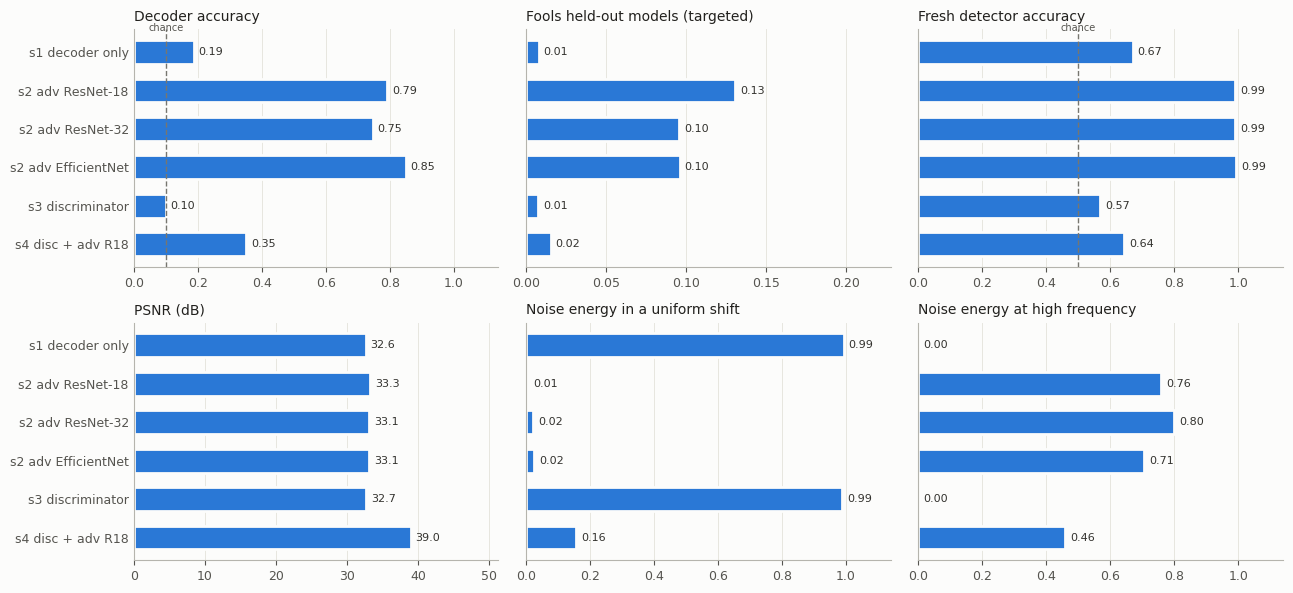

In [3]:
panels = [("decoder acc", "Decoder accuracy", (0, 1), .1), ("held-out: targeted", "Fools held-out models (targeted)", (0, .2), None),
          ("fresh detector", "Fresh detector accuracy", (0, 1), .5), ("PSNR", "PSNR (dB)", (0, 45), None),
          ("uniform-shift energy", "Noise energy in a uniform shift", (0, 1), None), ("high-freq energy", "Noise energy at high frequency", (0, 1), None)]
fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharey=True)
ypos = np.arange(len(metrics))[::-1]
for ax, (col, title, lim, ref) in zip(axes.flat, panels):
    vals = metrics[col].values
    ax.barh(ypos, np.array(vals) - lim[0], left=lim[0], height=.62, color="#2a78d6", edgecolor="#fcfcfb", linewidth=2)
    for y, v in zip(ypos, vals):
        ax.text(min(v, lim[1]) + (lim[1] - lim[0]) * .015, y, f"{v:.1f}" if col == "PSNR" else f"{v:.2f}", va="center", color="#33322e", fontsize=8)
    if ref is not None:
        ax.axvline(ref, color="#77766f", ls="--", lw=1); ax.text(ref, len(metrics) - .45, "chance", ha="center", color="#55544f", fontsize=7)
    ax.set_xlim(lim[0], lim[1] + (lim[1] - lim[0]) * .14); ax.set_title(title, loc="left", fontsize=10, color="#22211e")
    ax.set_yticks(ypos); ax.set_yticklabels(metrics.index); ax.tick_params(axis="y", length=0); ax.xaxis.grid(True, color="#e7e6df", lw=.7); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

## The noise on trucks hiding "deer"

Each encoder has two rows: the poisoned truck, then its noise amplified from [−ε, ε] to the full display range (mid-grey = no change). A flat coloured square means the noise is a uniform colour shift.

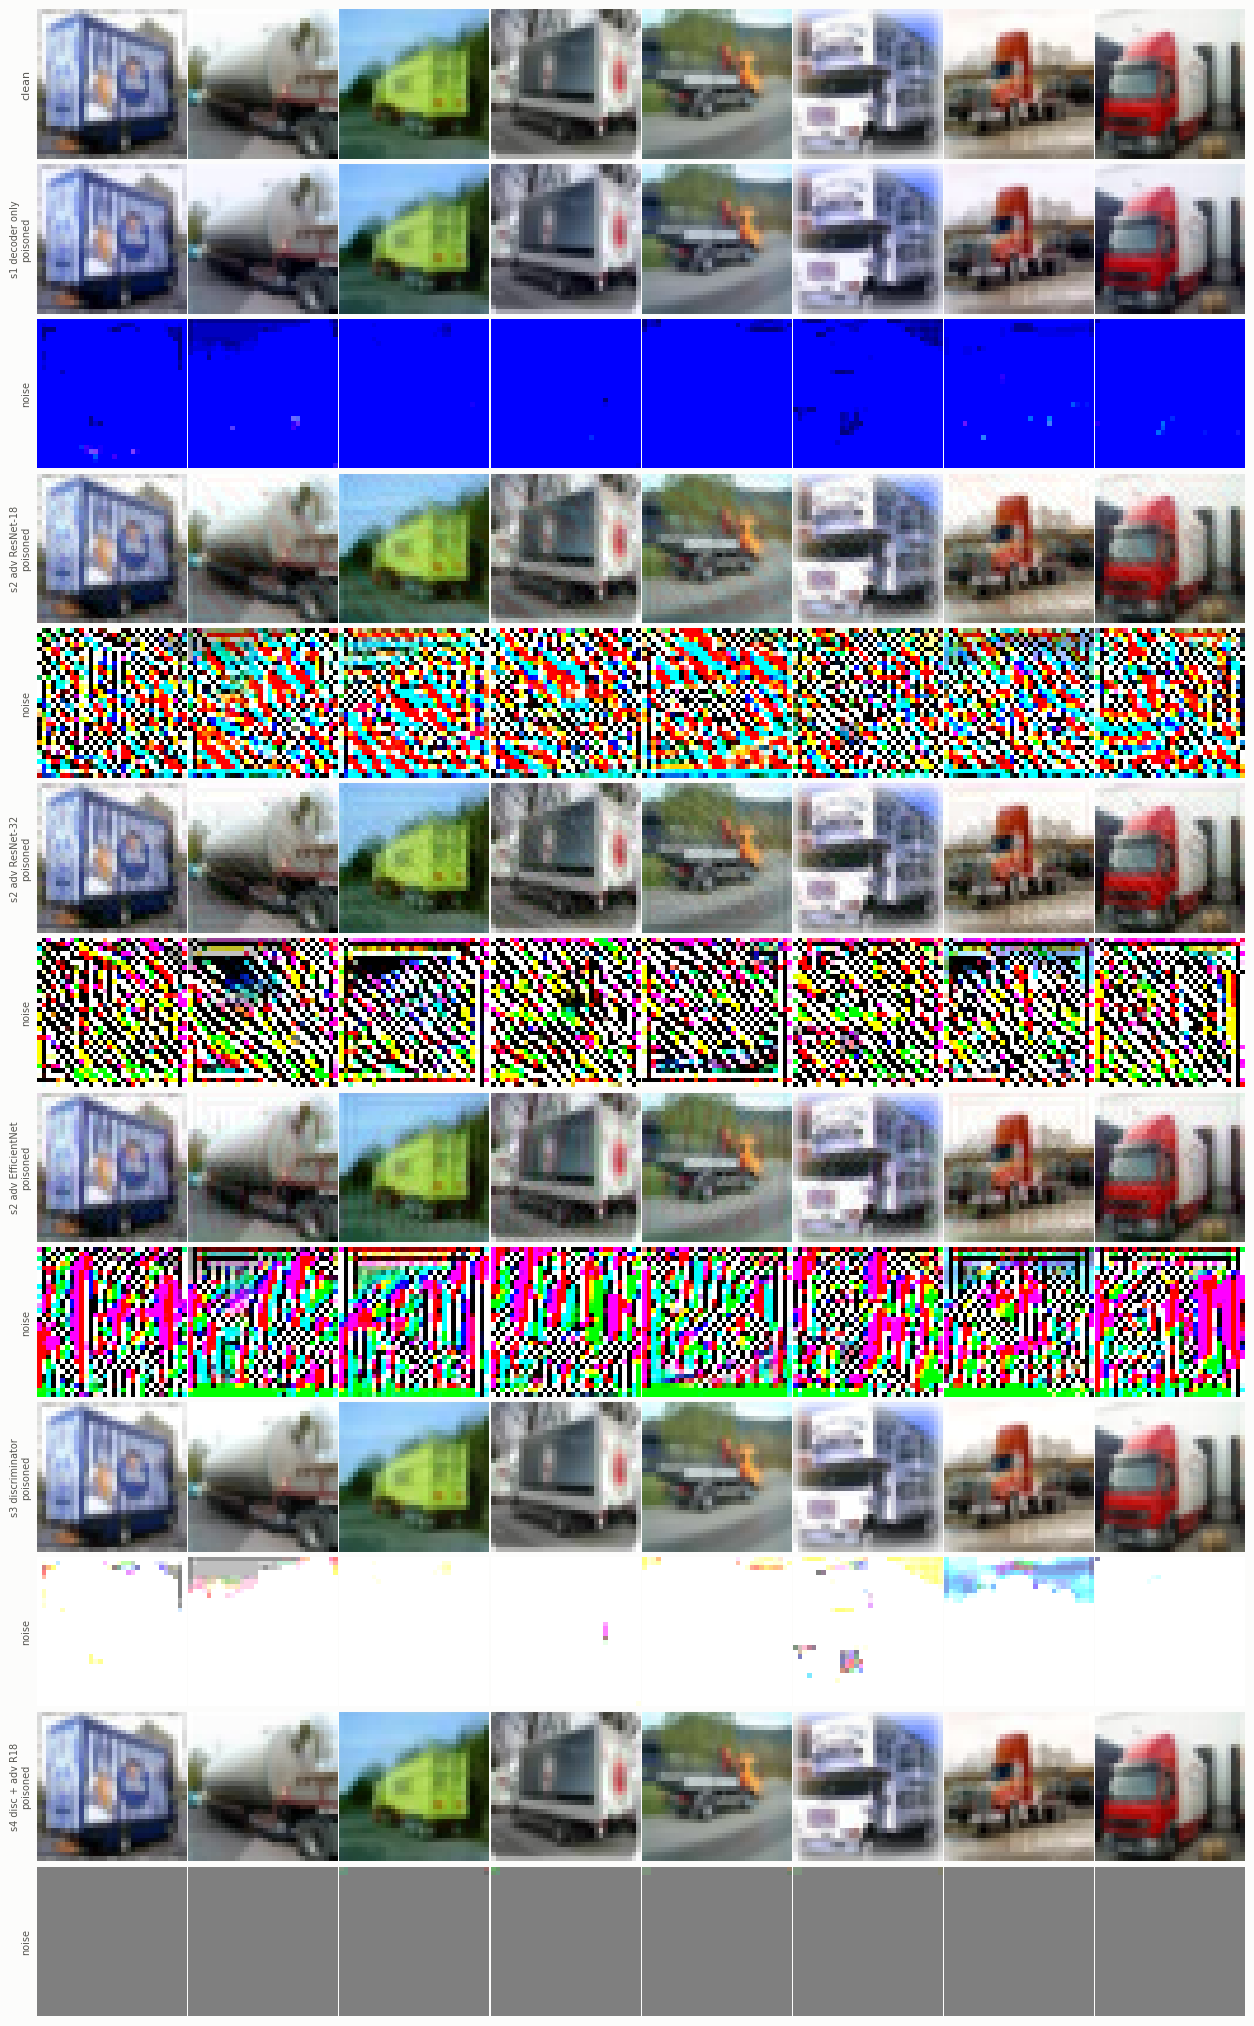

In [4]:
N = 8; idx = torch.randperm(len(trucks), generator=torch.Generator().manual_seed(1))[:N]
fig, ax = plt.subplots(1 + 2 * len(NAMES), N, figsize=(1.55 * N, 1.55 * (1 + 2 * len(NAMES))))
for c, i in enumerate(idx.tolist()):
    ax[0, c].imshow(img(trucks[i]))
    for r, n in enumerate(NAMES):
        xt = cache[n]["xt"][i]
        ax[1 + 2 * r, c].imshow(img(xt)); ax[2 + 2 * r, c].imshow(noise(xt - trucks[i], models[n]["eps"]))
ax[0, 0].set_ylabel("clean", fontsize=8)
for r, n in enumerate(NAMES):
    ax[1 + 2 * r, 0].set_ylabel(SHORT[n] + "\npoisoned", fontsize=7); ax[2 + 2 * r, 0].set_ylabel("noise", fontsize=7)
for a in ax.flat: a.set_xticks([]); a.set_yticks([]); [s.set_visible(False) for s in a.spines.values()]
plt.tight_layout(pad=.25); plt.show()

## Same image, each of the 10 hidden labels

If the columns of a row look identical, that encoder does not encode the label.

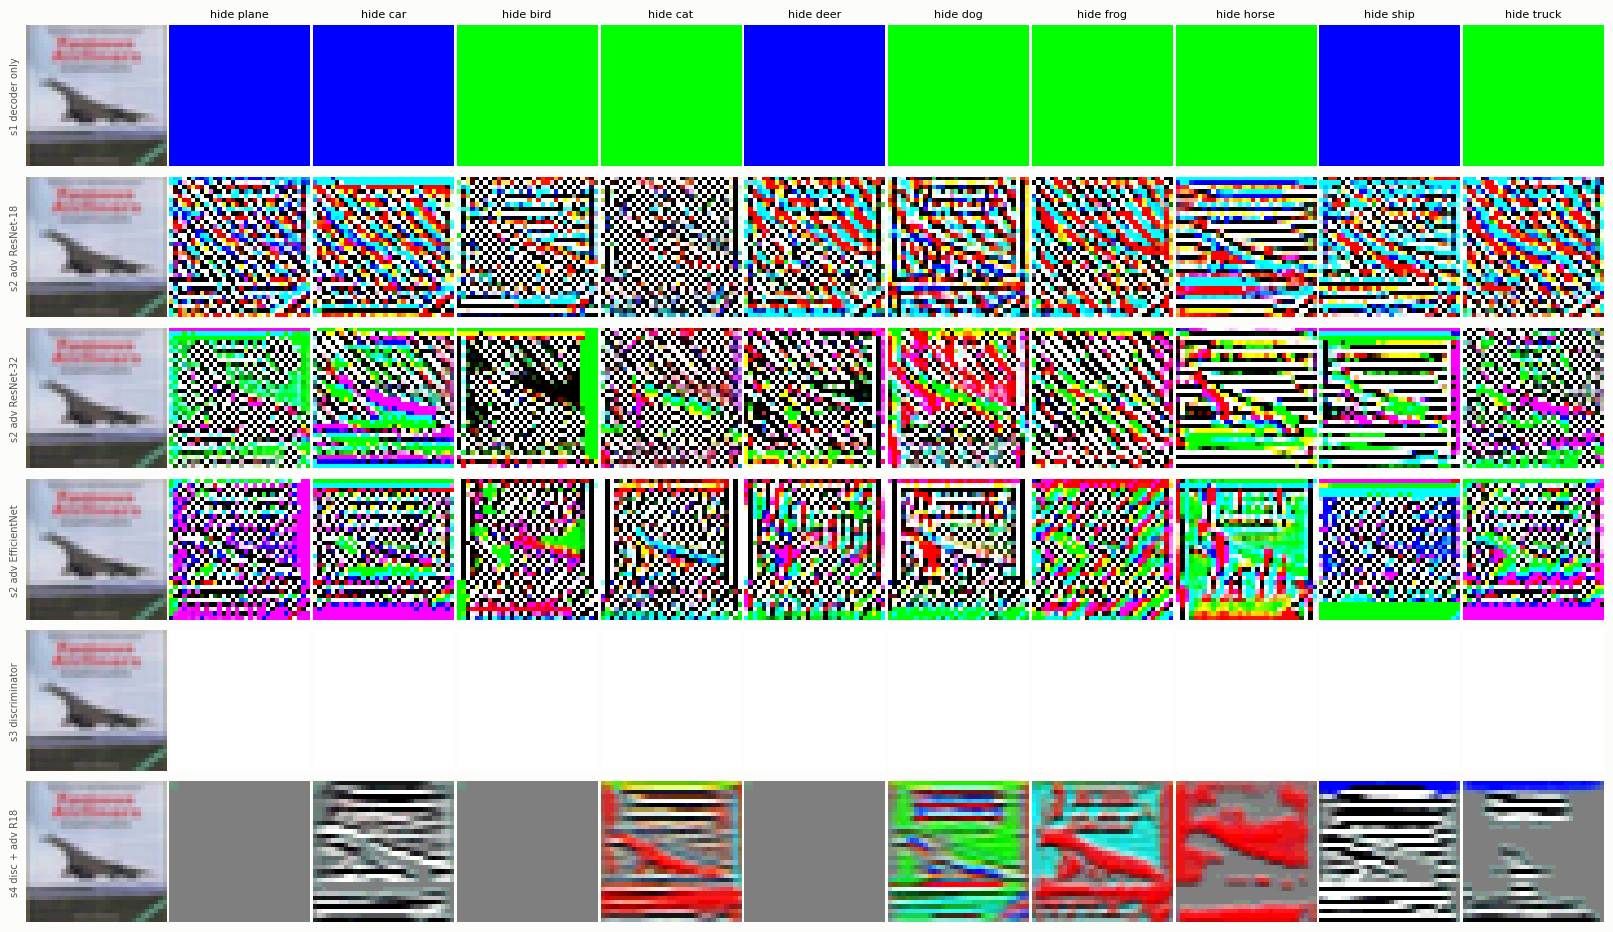

In [5]:
IMAGE = 3
fig, ax = plt.subplots(len(NAMES), 11, figsize=(16, 1.55 * len(NAMES)))
with torch.no_grad():
    x = x_test[IMAGE:IMAGE+1].expand(10, -1, -1, -1)
    for r, n in enumerate(NAMES):
        d = quantize_st(models[n]["enc"](x, torch.arange(10, device=device))) - x
        ax[r, 0].imshow(img(x_test[IMAGE])); ax[r, 0].set_ylabel(SHORT[n], fontsize=7)
        for c in range(10):
            ax[r, c + 1].imshow(noise(d[c], models[n]["eps"]))
            if r == 0: ax[r, c + 1].set_title(f"hide {CLASSES[c]}", fontsize=8)
for a in ax.flat: a.set_xticks([]); a.set_yticks([]); [s.set_visible(False) for s in a.spines.values()]
plt.tight_layout(pad=.25); plt.show()

## Mean noise per hidden label

Noise averaged over all 10,000 test images for each hidden label, rescaled per panel. What survives averaging is the part shared across images: a universal code for that label.

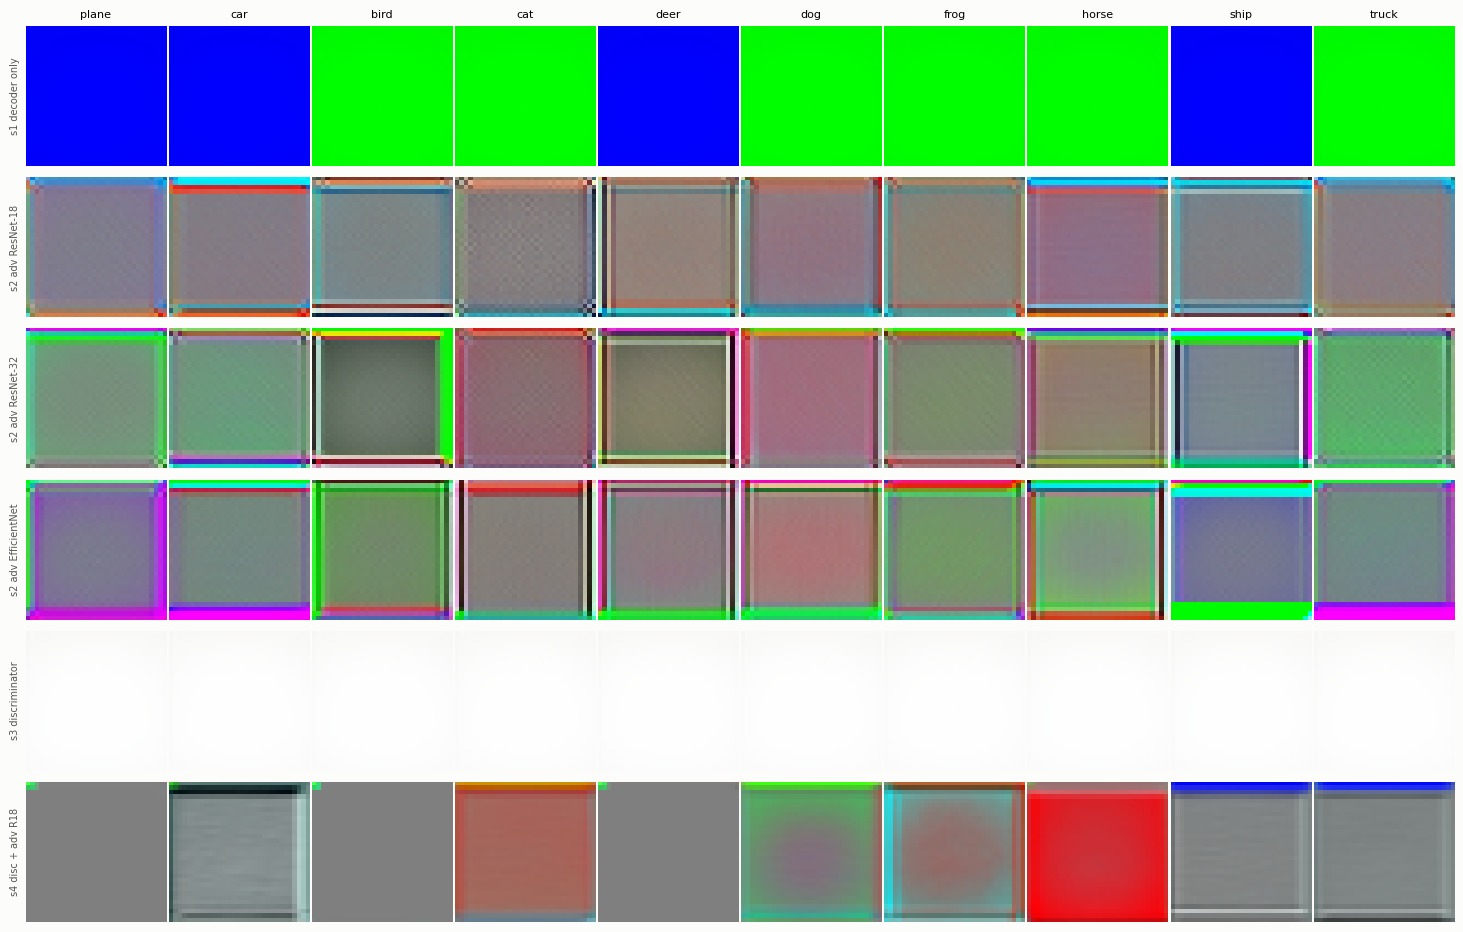

In [6]:
fig, ax = plt.subplots(len(NAMES), 10, figsize=(14.5, 1.55 * len(NAMES)))
with torch.no_grad():
    for r, n in enumerate(NAMES):
        for c in range(10):
            y = torch.full((len(x_test),), c, device=device)
            mu = (poison(models[n]["enc"], x_test, y) - x_test).mean(0)
            ax[r, c].imshow((mu / (2 * mu.abs().max().clamp_min(1e-6)) + .5).permute(1, 2, 0).cpu().numpy())
            if r == 0: ax[r, c].set_title(CLASSES[c], fontsize=8)
        ax[r, 0].set_ylabel(SHORT[n], fontsize=7)
for a in ax.flat: a.set_xticks([]); a.set_yticks([]); [s.set_visible(False) for s in a.spines.values()]
plt.tight_layout(pad=.25); plt.show()

## Noise power spectrum

Log power averaged over colour channels, with the zero frequency at the centre. A bright centre is a uniform shift; bright edges and corners are pixel-scale patterns.

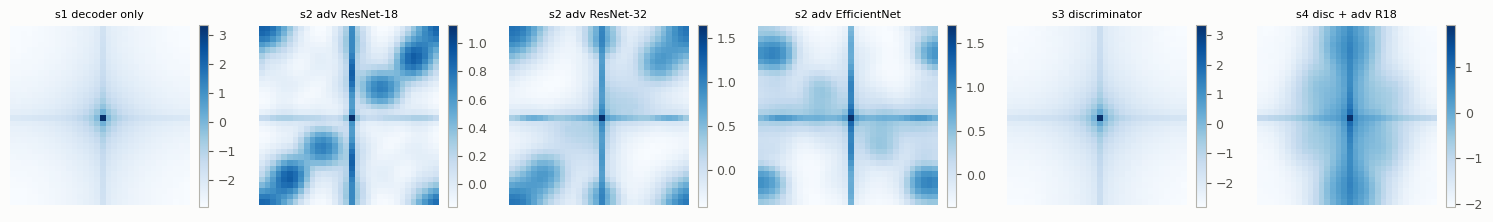

In [7]:
fig, ax = plt.subplots(1, 6, figsize=(15, 2.9))
for a, n in zip(ax, NAMES):
    s = torch.fft.fftshift(torch.fft.fft2(cache[n]["xp"] - x_test).abs().pow(2).mean((0, 1))).log10().cpu().numpy()
    im = a.imshow(s, cmap="Blues"); a.set_title(SHORT[n], fontsize=8); a.axis("off"); plt.colorbar(im, ax=a, fraction=.046)
plt.tight_layout(); plt.show()

## Decoder confusion matrices

A clean diagonal means the hidden label is recovered. A single dark column means the decoder always predicts the same class.

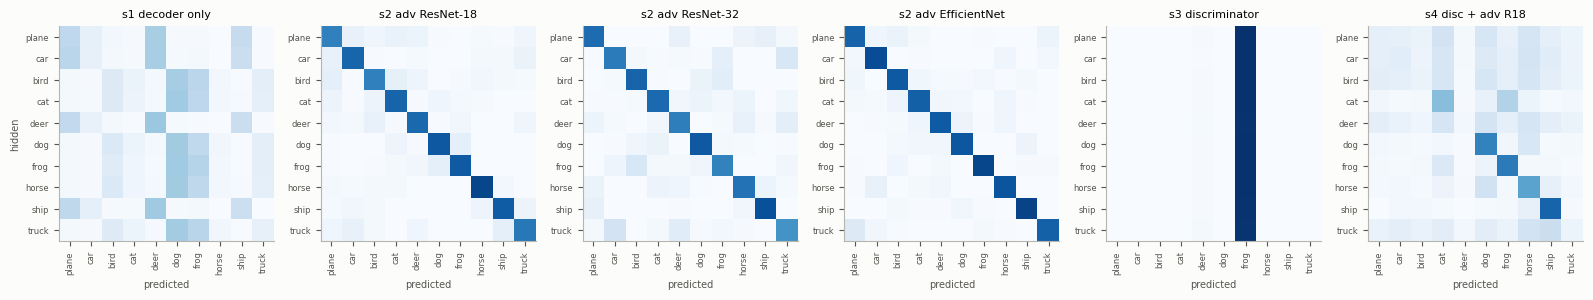

In [8]:
fig, ax = plt.subplots(1, 6, figsize=(16, 3))
for a, n in zip(ax, NAMES):
    C = np.zeros((10, 10)); np.add.at(C, (hidden.cpu().numpy(), cache[n]["p"].cpu().numpy()), 1)
    a.imshow(C / C.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1); a.set_title(SHORT[n], fontsize=8)
    a.set_xticks(range(10)); a.set_yticks(range(10)); a.set_xticklabels(CLASSES, rotation=90, fontsize=6); a.set_yticklabels(CLASSES, fontsize=6)
    a.set_xlabel("predicted", fontsize=7)
ax[0].set_ylabel("hidden", fontsize=7); plt.tight_layout(); plt.show()

## Training curves

The discriminator is switched on after epoch 5 in `s3` and `s4`.

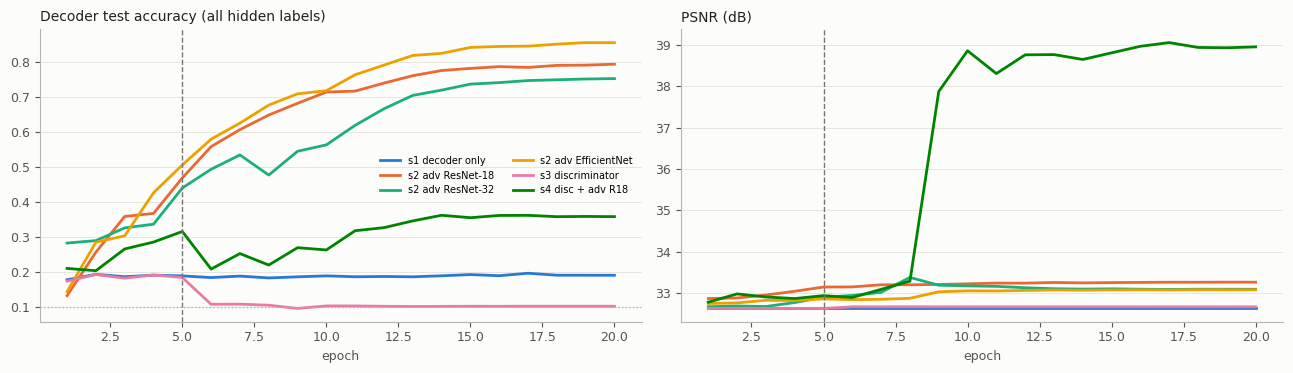

In [9]:
hist = {n: pd.DataFrame(json.load(open(ENC_DIR / f"{n}.json"))["history"]) for n in NAMES}
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for a, (col, title) in zip(ax, [("dec_acc", "Decoder test accuracy (all hidden labels)"), ("psnr", "PSNR (dB)")]):
    for n in NAMES:
        a.plot(hist[n].epoch, hist[n][col], color=COLORS[n], lw=2, label=SHORT[n])
    a.axvline(5, color="#77766f", ls="--", lw=1); a.set_title(title, loc="left", fontsize=10, color="#22211e")
    a.set_xlabel("epoch"); a.yaxis.grid(True, color="#e7e6df", lw=.7)
ax[0].axhline(.1, color="#b5b4ad", lw=1, ls=":"); ax[0].legend(frameon=False, fontsize=7, ncol=2)
plt.tight_layout(); plt.show()